# Chapter 9 - Modeling Probabilities and Nonlinearities: Activation Functions

## Summary
Introduces activation functions properly and the softmax output.
- **Activation function:** a function applied to a neuron's output; must be **nonlinear** (otherwise layers collapse into one linear map), **continuous**, and **monotonic-ish** with a usable derivative.
- **Hidden-layer choices:** ReLU, sigmoid, tanh (tanh often beats sigmoid because it is zero-centred and can output negative correlations).
- **Output-layer choices:** identity (regression), sigmoid (independent yes/no predictions), **softmax** (exactly one class among many).
- **Softmax:** `exp(x_i) / sum(exp(x))` turns scores into a probability distribution and increases confidence.
- **Cross-entropy / softmax gradient:** with softmax, `delta = pred - target` stays simple; the net learns faster.

## Theory
| Function | Formula | Derivative | Notes |
|---|---|---|---|
| ReLU | max(0,x) | 1 if x>0 else 0 | cheap; common default |
| Sigmoid | 1/(1+e^-x) | s(1-s) | squashes to (0,1); saturates |
| Tanh | (e^x-e^-x)/(e^x+e^-x) | 1 - t^2 | squashes to (-1,1); zero-centred |
| Softmax | e^xi / sum e^xj | pred - target (with cross-entropy) | probabilities summing to 1 |

**Why softmax?** Raw outputs for different classes are independent; exponentials make big scores bigger, and normalising gives a probability that competes between classes. During training a neuron's wrong prediction is penalised but *a correct class is also pushed up while others fall*.
Note: the book uses tanh in the hidden layer and softmax output with the tanh derivative `1 - output^2`.

In [1]:
# If numpy / scikit-learn are missing in this kernel, uncomment:
# %pip install numpy scikit-learn
import numpy as np

In [2]:
# Dataset: scikit-learn's bundled 8x8 handwritten digits (offline stand-in for MNIST's 28x28).
# The code is identical in spirit; only image size differs. Swap in MNIST if you like.
from sklearn.datasets import load_digits
digits = load_digits()
X = digits.data / 16.0                      # pixels scaled to 0..1
y = digits.target
labels = np.eye(10)[y]                      # one-hot
n_train = 1000
images, train_labels = X[:n_train], labels[:n_train]
test_images, test_labels = X[n_train:], labels[n_train:]
print(images.shape, test_images.shape)

(1000, 64) (797, 64)


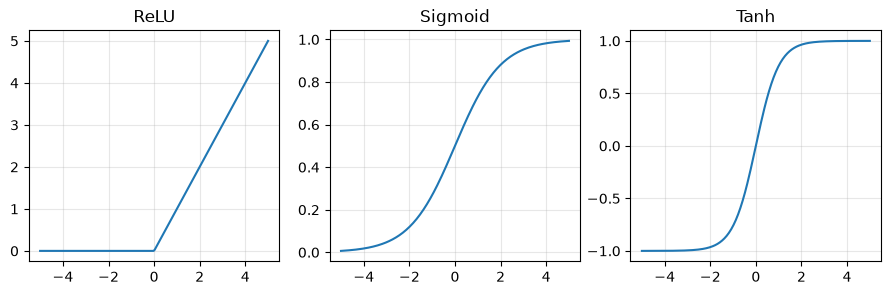

In [3]:
import matplotlib.pyplot as plt
x = np.linspace(-5, 5, 200)
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
for a, (n, f) in zip(ax, [("ReLU", lambda v: np.maximum(0, v)), ("Sigmoid", lambda v: 1/(1+np.exp(-v))), ("Tanh", np.tanh)]):
    a.plot(x, f(x)); a.set_title(n); a.grid(alpha=.3)
plt.show()

In [4]:
def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))   # subtract max for numerical stability
    return e / e.sum(axis=1, keepdims=True)
print(softmax(np.array([[1., 2., 3.]])))
print(softmax(np.array([[10., 20., 30.]])))   # sharper with bigger gaps

[[0.09003057 0.24472847 0.66524096]]
[[2.06106005e-09 4.53978686e-05 9.99954600e-01]]


In [5]:
tanh = np.tanh
tanh2deriv = lambda out: 1 - out ** 2

np.random.seed(1)
alpha, hidden, batch_size, iters = 2.0, 100, 100, 300
w01 = 0.02 * np.random.random((images.shape[1], hidden)) - 0.01
w12 = 0.2 * np.random.random((hidden, 10)) - 0.1

for j in range(iters):
    correct = 0
    for i in range(len(images) // batch_size):
        s, e = i * batch_size, (i + 1) * batch_size
        l0 = images[s:e]
        l1 = tanh(l0.dot(w01))
        mask = np.random.randint(2, size=l1.shape)
        l1 *= mask * 2
        l2 = softmax(l1.dot(w12))
        correct += np.sum(np.argmax(l2, 1) == np.argmax(train_labels[s:e], 1))
        d2 = (train_labels[s:e] - l2) / (batch_size * l2.shape[0])
        d1 = d2.dot(w12.T) * tanh2deriv(l1) * mask
        w12 += alpha * l1.T.dot(d2)
        w01 += alpha * l0.T.dot(d1)
    if j % 50 == 0 or j == iters - 1:
        l2t = softmax(tanh(test_images.dot(w01)).dot(w12))
        print(f"I:{j:4d} Train-Acc:{correct/len(images):.3f} "
              f"Test-Acc:{np.mean(np.argmax(l2t,1)==np.argmax(test_labels,1)):.3f}")

I:   0 Train-Acc:0.096 Test-Acc:0.132
I:  50 Train-Acc:0.793 Test-Acc:0.758
I: 100 Train-Acc:0.868 Test-Acc:0.839
I: 150 Train-Acc:0.916 Test-Acc:0.890
I: 200 Train-Acc:0.933 Test-Acc:0.906
I: 250 Train-Acc:0.955 Test-Acc:0.911
I: 299 Train-Acc:0.963 Test-Acc:0.913


## Takeaways
Pick activations by role: nonlinear for hidden layers, softmax for single-label classification. Softmax + cross-entropy gives a clean gradient and probability-like outputs.